# Assignment 5 — Clustering and Initialization

**Objective.** Compare standard random initialization with K-means++ , using the same K-means implementation on a synthetic dataset and MNIST. We evaluate the **inertia distribution across 30 independent trials with 30 different seed**;

The clustering algorithms are implemented from scratch using NumPy. Scikit-learn is used **only** to generate the synthetic dataset.

In [11]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs

N_TRIALS = 30
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. K-means and K-means++ from scratch

K-means alternates between assigning each point to its nearest centroid and updating each centroid to the mean of its assigned points. K-means++ selects the first center uniformly and each subsequent center with probability proportional to the **squared distance to the nearest previously selected center**. The Lloyd iterations are identical for both methods.

In [ ]:
def squared_distances(X, centroids):
    x_norm = np.sum(X**2, axis=1)[:, None]
    c_norm = np.sum(centroids**2, axis=1)[None, :]
    #scomposizione del calcolo delle distanze euclidee.
    return np.maximum(x_norm + c_norm - 2 * X @ centroids.T, 0.0)


def kmeans_plus_plus_init(X, k, rng):
    
    first_idx = rng.integers(len(X))
    selected = [first_idx]
    #alcola la distanza quadratica per ogni punto
    min_dist_sq = np.sum((X - X[first_idx]) ** 2, axis=1)

    for _ in range(1, k):
        # per evitare che vengano estratti nuovamente centroidi selezionati
        min_dist_sq[selected] = 0
        total = np.sum(min_dist_sq)

        if total == 0:
            available = np.setdiff1d(np.arange(len(X)), selected)
            next_idx = rng.choice(available)
        else:
            #eleziona indice del prossimo centroide
            next_idx = rng.choice(len(X), p=min_dist_sq / total)

        selected.append(next_idx)
        new_dist_sq = np.sum((X - X[next_idx]) ** 2, axis=1)
         #per ogni punto mantiene la distanza quadratica dal centroide selezionato piu vicino.
        min_dist_sq = np.minimum(min_dist_sq, new_dist_sq)
    #matrice contente le cordinate dei centroidi
    return X[selected].copy()


def kmeans(X, k, max_iter=100, seed=42, init="random"):

    rng = np.random.default_rng(seed)
    if init == "random":
        indices = rng.choice(len(X), size=k, replace=False)
        centroids = X[indices].copy()
    elif init == "kmeans++":
        centroids = kmeans_plus_plus_init(X, k, rng)
 
    for _ in range(max_iter):
        labels = np.argmin(squared_distances(X, centroids), axis=1)
        new_centroids = centroids.copy()

        for j in range(k):
            #seleziona tutti i punti assegnati al cluster j
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                #calcola il nuovo centroide
                new_centroids[j] = np.mean(cluster_points, axis=0)
        #Per verificare la convergenza
        converged = np.allclose(centroids, new_centroids)
        centroids = new_centroids
        if converged:
            break

    labels = np.argmin(squared_distances(X, centroids), axis=1)
    #Calcola inerzia
    inertia = float(np.sum((X - centroids[labels]) ** 2))
    return centroids, labels, inertia

## 2. Shared experimental protocol

For each dataset and each initialization method, run K-means with **30 seeds (0–29)**, the **same number of clusters**, and at most **100 iterations**. We compare mean, standard deviation, median, minimum and maximum inertia. Boxplots summarize the distributions. Using the same seed values makes the experiment reproducible; it does not force the two initialization methods to pick identical initial centers.

In [ ]:
def run_trials(X, k, n_trials=N_TRIALS):
    #ritorna 30 inerzia per random e kmean++
    return {
        method: np.array([
            kmeans(X, k=k, max_iter=100, seed=seed, init=method)[2]
            for seed in range(n_trials)
        ])
        for method in ("random", "kmeans++")
    }


def print_summary(dataset_name, results):
    print(f"\n{dataset_name} — inertia over {len(results['random'])} trials")
    print(f"{'Method':<12} {'Mean':>12} {'Std':>12} {'Median':>12} {'Min':>12} {'Max':>12}")
    for method, values in results.items():
        print(f"{method:<12} {values.mean():>12.2f} {values.std():>12.2f} "
              f"{np.median(values):>12.2f} {values.min():>12.2f} {values.max():>12.2f}")

def plot_inertias(results, title, filename, log_scale=False):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.boxplot([results['random'], results['kmeans++']], showmeans=True)
    ax.set_xticks([1, 2], ["K-means Random", "K-means++"])
    ax.set_title(title)
    ax.set_ylabel("Inertia" + (" (log scale)" if log_scale else ""))
    if log_scale:
        ax.set_yscale("log")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=300)
    plt.show()

## 3. Synthetic dataset (2 features, 4 clusters)

Generate 600 points around four well-separated centers with standard deviation 1.3. The synthetic dataset is deliberately designed to have good clustering structure.

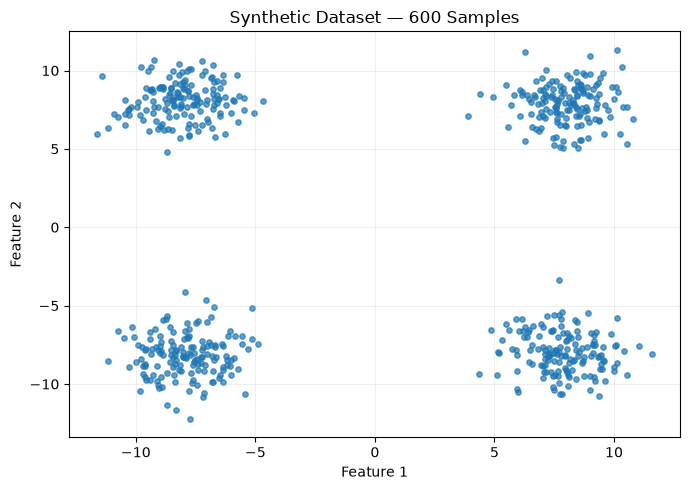

In [14]:
X_synthetic, _ = make_blobs(
    n_samples=600,
    centers=[[-8, -8], [-8, 8], [8, -8], [8, 8]],
    cluster_std=1.3,
    random_state=123,
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_synthetic[:, 0], X_synthetic[:, 1], s=15, alpha=0.7)
ax.set(title="Synthetic Dataset — 600 Samples", xlabel="Feature 1", ylabel="Feature 2")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "synthetic_dataset.png", dpi=300)
plt.show()


Synthetic dataset — inertia over 30 trials
Method               Mean          Std       Median          Min          Max
random           10830.32     10650.61      2002.70      2002.70     40173.33
kmeans++          2625.91      3356.11      2002.70      2002.70     20699.13


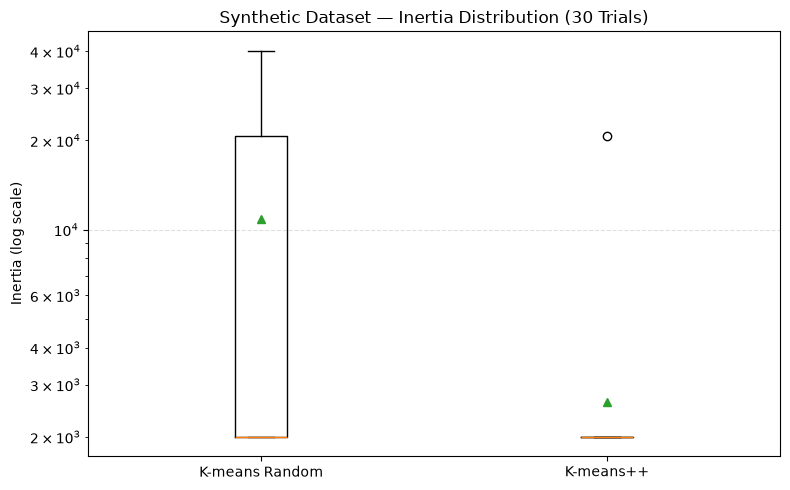

In [15]:
synthetic_results = run_trials(X_synthetic, k=4)
print_summary("Synthetic dataset", synthetic_results)
plot_inertias(
    synthetic_results,
    "Synthetic Dataset — Inertia Distribution (30 Trials)",
    "synthetic_inertia_boxplot.png",
    log_scale=True,
)

In [ ]:

best_inertia = min(values.min() for values in synthetic_results.values())
threshold = 1.05 * best_inertia
print(f"Best observed inertia: {best_inertia:.2f}; threshold (+5%): {threshold:.2f}")
for method, values in synthetic_results.items():
    #calcola percentuale near-best runs per random e kmeanss++
    print(f"{method}: {100 * np.mean(values <= threshold):.1f}% near-best runs")

Best observed inertia: 2002.70; threshold (+5%): 2102.83
random: 56.7% near-best runs
kmeans++: 96.7% near-best runs


## 4. MNIST (784 features, 10 clusters)

Use a reproducible sample of 5,000 images from the **60,000-image MNIST training set**. Each 28×28 image is flattened to 784 features and pixel intensities are scaled to [0, 1]. Class labels are used **only for visualization**, never for clustering.

The compressed `.npz` file is cached in `data/`. The first run downloads it; subsequent runs reuse the local copy. The dataset is not generated with scikit-learn.

In [ ]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
mnist_path = DATA_DIR / "mnist.npz"

if not mnist_path.exists():
    urlretrieve(
        "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
        mnist_path,
    )

with np.load(mnist_path) as data:
    images = data["x_train"]
    targets = data["y_train"]

sample_indices = np.random.default_rng(42).choice(
    len(images), size=5000, replace=False
)
#trasforma ogni matrice 28x28 in un vettore di 784 numeri + normalizzazione
X_mnist = images[sample_indices].reshape(5000, 784).astype(np.float32) / 255.0
y_mnist = targets[sample_indices]

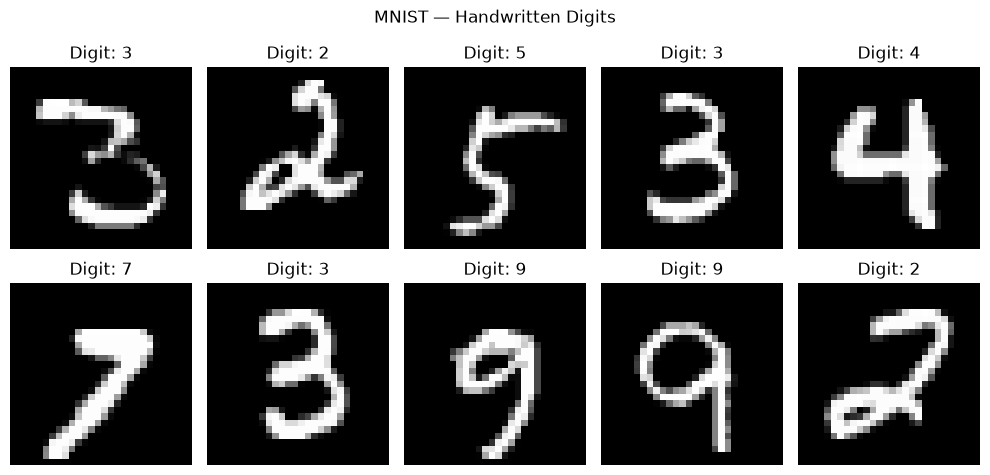

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_mnist[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Digit: {y_mnist[i]}")
    ax.axis("off")
fig.suptitle("MNIST — Handwritten Digits")
fig.tight_layout()
plt.show()


MNIST — inertia over 30 trials
Method               Mean          Std       Median          Min          Max
random          196865.37       646.09    196723.45    196153.53    198598.44
kmeans++        196672.12       417.94    196632.73    196135.53    197526.03


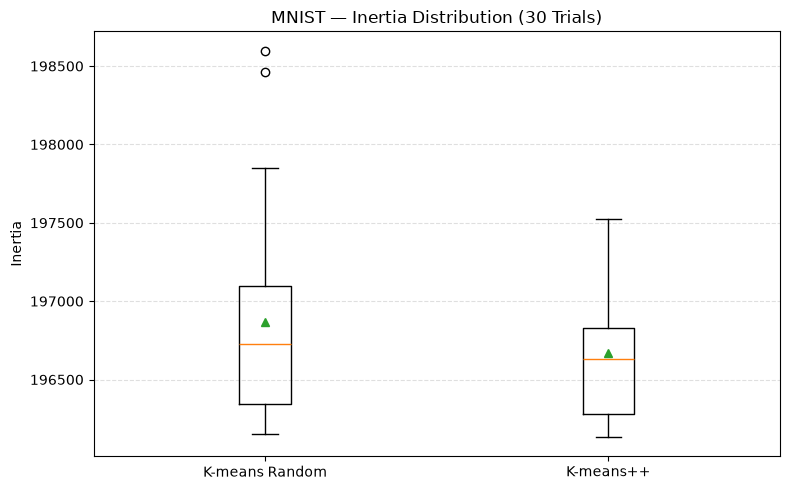

In [19]:
mnist_results = run_trials(X_mnist, k=10)
print_summary("MNIST", mnist_results)
plot_inertias(
    mnist_results,
    "MNIST — Inertia Distribution (30 Trials)",
    "mnist_inertia_boxplot.png",
)

## 5. Cross-dataset comparison

Percentage changes compare the two initialization methods **within each dataset**. Raw inertia values should not be compared across datasets because the number of points, dimensions and cluster counts differ.

A smaller standard deviation across seeds indicates less variability in the achieved inertia value; it does **not** by itself measure agreement between cluster assignments.

In [ ]:
print(f"{'Dataset':<12} {'Mean inertia reduction':>24} {'Std reduction':>18}")
for name, results in [("Synthetic", synthetic_results), ("MNIST", mnist_results)]:
    random_vals, plus_vals = results["random"], results["kmeans++"]
    #calcola la riduzione in percentuale
    mean_reduction = 100 * (random_vals.mean() - plus_vals.mean()) / random_vals.mean()
    std_reduction = 100 * (random_vals.std() - plus_vals.std()) / random_vals.std()
    print(f"{name:<12} {mean_reduction:>23.2f}% {std_reduction:>17.2f}%")

Dataset        Mean inertia reduction      Std reduction
Synthetic                      75.75%             68.49%
MNIST                           0.10%             35.31%
